In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

print("All imports completed successfully!")

All imports completed successfully!


In [3]:
url = (
    "https://raw.githubusercontent.com/IBM/"
    "telco-customer-churn-on-icp4d/master/data/"
    "Telco-Customer-Churn.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully!
Dataset shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [4]:
# Display all column names
print("COLUMN NAMES:")
print(df.columns.tolist())

# Check data types and non-null values
print("\nDATASET INFORMATION:")
df.info()

# Check missing values
print("\nMISSING VALUES:")
print(df.isnull().sum())

# Check customer churn distribution
print("\nCHURN DISTRIBUTION:")
print(df["Churn"].value_counts())

COLUMN NAMES:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

DATASET INFORMATION:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecur

In [6]:
# Here now we calculate th epercentage of customers who left the company
total_customers = 7043
churned_customers = 1869

churn_rate = (churned_customers / total_customers) * 100

print("Customer Churn Rate:", round(churn_rate, 2), "%")

Customer Churn Rate: 26.54 %


In [7]:
# Checking data type of TotalCharges
print("TotalCharges data type:")
print(df["TotalCharges"].dtype)

# Finding empty spaces values
empty_values = df["TotalCharges"].str.strip().eq("").sum()

print("\nNumber of empty TotalCharges values:")
print(empty_values)

# Display examples
print("\nSample TotalCharges values:")
print(df["TotalCharges"].head(15))

TotalCharges data type:
object

Number of empty TotalCharges values:
11

Sample TotalCharges values:
0       29.85
1      1889.5
2      108.15
3     1840.75
4      151.65
5       820.5
6      1949.4
7       301.9
8     3046.05
9     3487.95
10     587.45
11      326.8
12     5681.1
13     5036.3
14    2686.05
Name: TotalCharges, dtype: object


In [8]:
# Find customers with empty TotalCharges
empty_rows = df[df["TotalCharges"].str.strip() == ""]

# Display their important information
display(
    empty_rows[
        ["customerID", "tenure", "MonthlyCharges",
         "TotalCharges", "Churn"]
    ]
)

,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


In [11]:
# Check whether all empty TotalCharges rows have zero tenure
print("Tenure values in empty rows:")
print(empty_rows["tenure"].value_counts())

# Check the number of empty rows
print("\nTotal empty rows:", len(empty_rows))

Tenure values in empty rows:
tenure
0    11
Name: count, dtype: int64

Total empty rows: 11


In [10]:
# Data Cleaning

# Remove extra spaces from TotalCharges
df["TotalCharges"] = df["TotalCharges"].str.strip()

# Replace empty values with zero
df["TotalCharges"] = df["TotalCharges"].replace("", "0")

# Convert TotalCharges into numeric values
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"])

# Check the updated data type
print("Updated data type:", df["TotalCharges"].dtype)

# Check for missing values again
print("\nMissing values after cleaning:")
print(df.isnull().sum().sum())

Updated data type: float64

Missing values after cleaning:
0


#### SQL ANALYSIS

In [12]:
import sqlite3

# Create a database for customer data
conn = sqlite3.connect("customer_churn.db")

# Save the cleaned data into a SQL table
df.to_sql("customers", conn, if_exists="replace", index=False)

print("Customer data saved successfully!")

Customer data saved successfully!


In [17]:
# Count all customers in the database

query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""

result = pd.read_sql_query(query, conn)

display(result)

,total_customers
0,7043


### Customer Churn Analysis Using SQL

In [19]:
# Count customers based on their churn status
query = """
SELECT
    Churn,
    COUNT(*) AS Customer_count
FROM customers
GROUP BY Churn;
"""

result = pd.read_sql_query(query, conn)

display(result)

,Churn,Customer_count
0,No,5174
1,Yes,1869


In [20]:
# Calculate the percentage of customers who left
query = """
SELECT
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate
FROM customers;
"""

result = pd.read_sql_query(query, conn)

display(result)

,total_customers,churned_customers,churn_rate
0,7043,1869,26.54


### Relation of Contract Type With Customer Churn

In [21]:
# Compare customer churn across different contract types
query = """
SELECT
    Contract,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate
FROM customers
GROUP BY Contract
ORDER BY churn_rate DESC;
"""

result = pd.read_sql_query(query, conn)

display(result)

,Contract,total_customers,churned_customers,churn_rate
0,Month-to-month,3875,1655,42.71
1,One year,1473,166,11.27
2,Two year,1695,48,2.83


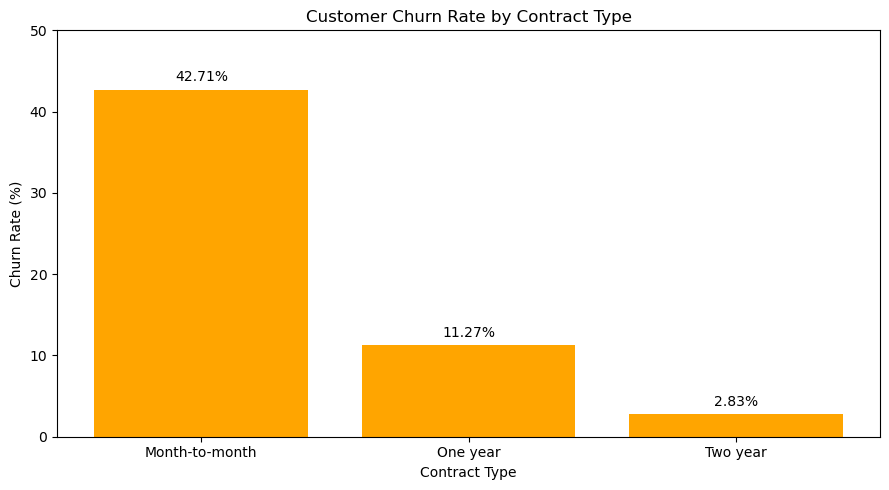

In [35]:
import matplotlib.pyplot as plt

# Create a bar chart to compare churn rates by contract type
plt.figure(figsize=(9, 5))

plt.bar(
    result["Contract"],
    result["churn_rate"],
    color="orange"
)

# Add labels and title
plt.title("Customer Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate (%)")

# Display the churn rate above each bar
for i, value in enumerate(result["churn_rate"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()

plt.show()

### Payment Method Analysis

In [32]:
# Compare customer churn across different payment methods
query = """
SELECT
    PaymentMethod,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate
FROM customers
GROUP BY PaymentMethod
ORDER BY churn_rate DESC;
"""

result_payment = pd.read_sql_query(query, conn)

display(result_payment)

,PaymentMethod,total_customers,churned_customers,churn_rate
0,Electronic check,2365,1071,45.29
1,Mailed check,1612,308,19.11
2,Bank transfer (automatic),1544,258,16.71
3,Credit card (automatic),1522,232,15.24


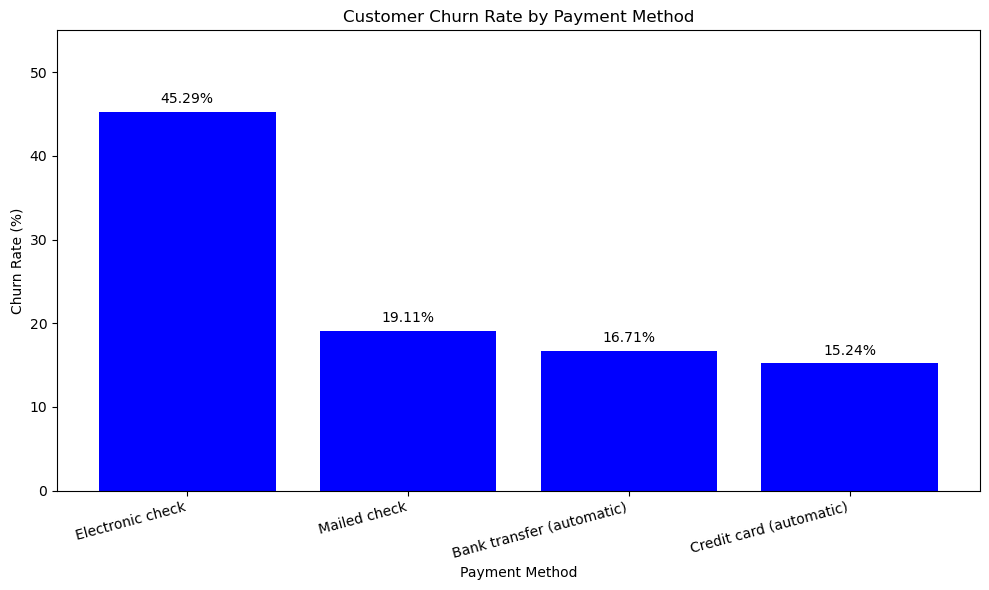

In [38]:
# Compare churn rates for different payment methods
plt.figure(figsize=(10, 6))

plt.bar(
    result_payment["PaymentMethod"],
    result_payment["churn_rate"],
    color="blue"
)

# Add title and axis labels
plt.title("Customer Churn Rate by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Churn Rate (%)")

# Display percentages above the bars
for i, value in enumerate(result_payment["churn_rate"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.xticks(rotation=15, ha="right")
plt.ylim(0, 55)
plt.tight_layout()

plt.show()

### Internet Service Analysis

In [39]:
# Compare customer churn across internet service types
query = """
SELECT
    InternetService,
    COUNT(*) AS total_customers,
    SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
        100.0 * SUM(CASE WHEN Churn = 'Yes' THEN 1 ELSE 0 END)
        / COUNT(*), 2
    ) AS churn_rate
FROM customers
GROUP BY InternetService
ORDER BY churn_rate DESC;
"""

result_internet = pd.read_sql_query(query, conn)

display(result_internet)

,InternetService,total_customers,churned_customers,churn_rate
0,Fiber optic,3096,1297,41.89
1,DSL,2421,459,18.96
2,No,1526,113,7.40


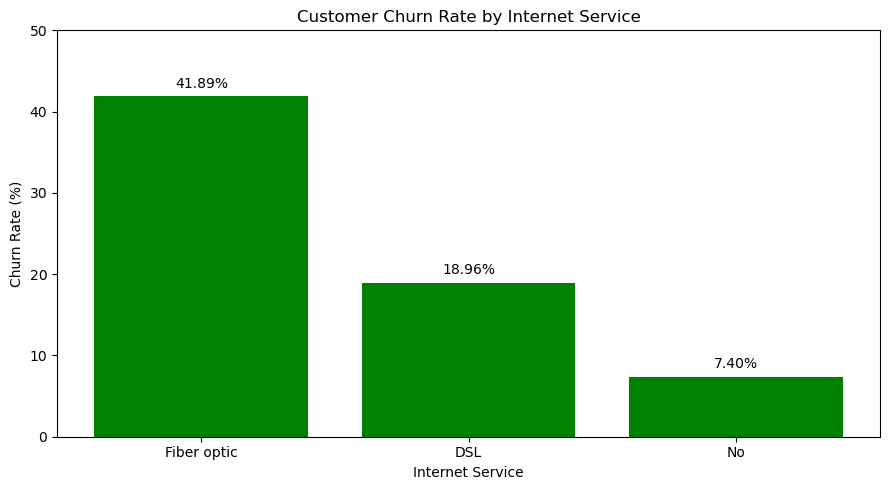

In [43]:
# Compare churn rates across internet services
plt.figure(figsize=(9, 5))

plt.bar(
    result_internet["InternetService"],
    result_internet["churn_rate"],
    color="green"
)

plt.title("Customer Churn Rate by Internet Service")
plt.xlabel("Internet Service")
plt.ylabel("Churn Rate (%)")

for i, value in enumerate(result_internet["churn_rate"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, 50)
plt.tight_layout()
plt.show()

### Exploratory Data Analysis (EDA)
  #### Customer Tenure Analysis

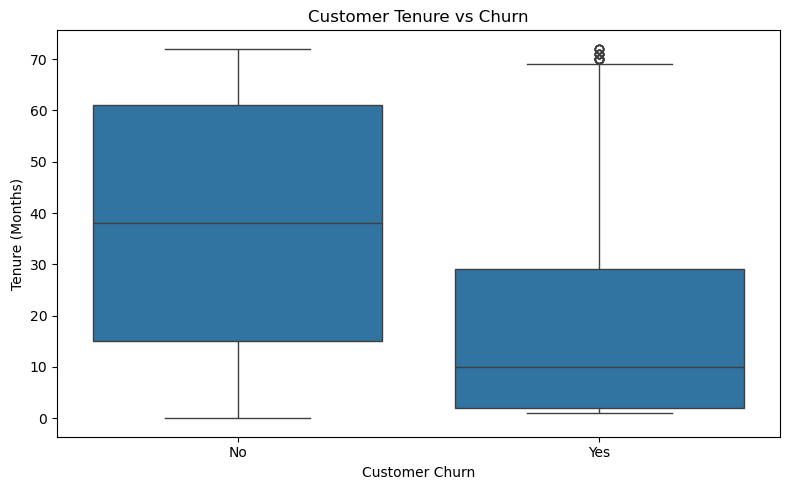

In [44]:
# Compare customer tenure for churned and active customers
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Churn",
    y="tenure",
    data=df
)

plt.title("Customer Tenure vs Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Tenure (Months)")

plt.tight_layout()
plt.show()

### Monthly Charges Analysis

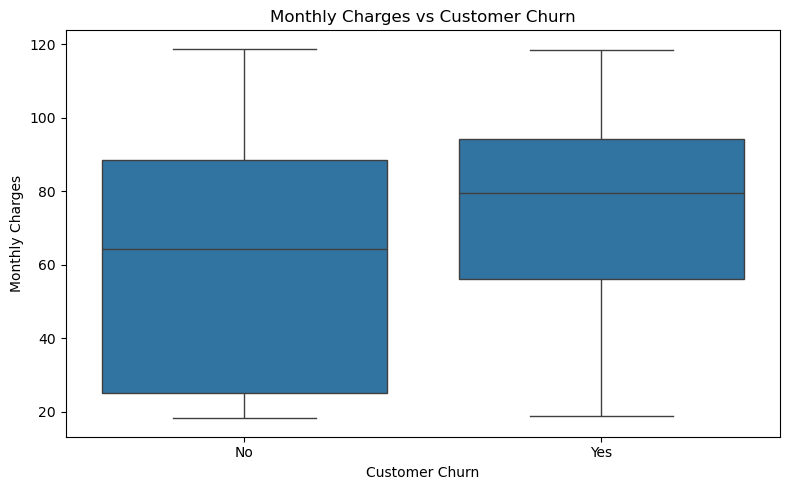

In [45]:
# Compare monthly charges for churned and active customers
plt.figure(figsize=(8, 5))

sns.boxplot(
    x="Churn",
    y="MonthlyCharges",
    data=df
)

plt.title("Monthly Charges vs Customer Churn")
plt.xlabel("Customer Churn")
plt.ylabel("Monthly Charges")

plt.tight_layout()
plt.show()

### Correlation Analysis

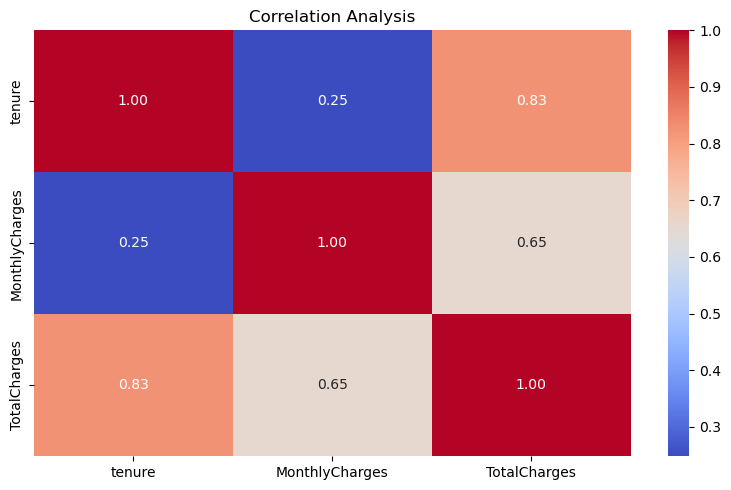

In [46]:
# Select numerical columns for correlation analysis
numeric_df = df[
    ["tenure", "MonthlyCharges", "TotalCharges"]
]

# Calculate correlation between the variables
correlation = numeric_df.corr()

# Display correlation heatmap
plt.figure(figsize=(8, 5))
sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Analysis")
plt.tight_layout()
plt.show()

### Data Preparation for Machine learning

In [47]:
# Check data types of all columns
print(df.dtypes)

customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges        float64
Churn                object
dtype: object


In [48]:
# Separate input features and target variable
X = df.drop(columns=["customerID", "Churn"])
y = df["Churn"].map({"No": 0, "Yes": 1})

# Convert categorical columns into numerical values
X = pd.get_dummies(X, drop_first=True, dtype=int)

# Check the prepared data
print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())

Features shape: (7043, 30)
Target shape: (7043,)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Male,Partner_Yes,Dependents_Yes,PhoneService_Yes,MultipleLines_No phone service,MultipleLines_Yes,...,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_One year,Contract_Two year,PaperlessBilling_Yes,PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,1,29.85,29.85,0,1,0,0,1,0,...,0,0,0,0,0,0,1,0,1,0
1,0,34,56.95,1889.50,1,0,0,1,0,0,...,0,0,0,0,1,0,0,0,0,1
2,0,2,53.85,108.15,1,0,0,1,0,0,...,0,0,0,0,0,0,1,0,0,1
3,0,45,42.30,1840.75,1,0,0,0,1,0,...,0,0,0,0,1,0,0,0,0,0
4,0,2,70.70,151.65,0,0,0,1,0,0,...,0,0,0,0,0,0,1,0,1,0


### Split the Dataset (Train and Test Data)

In [49]:
# Split data into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Check the size of each dataset
print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)
print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (5634, 30)
Testing features: (1409, 30)
Training target: (5634,)
Testing target: (1409,)


### Logistic Regression

In [50]:
# Import the required machine learning tools
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Create the logistic regression model
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

# Train the model using training data
model.fit(X_train, y_train)

print("Logistic Regression model trained successfully!")

Logistic Regression model trained successfully!


### Model Prediction

In [51]:
# Predict customer churn using test data
y_pred = model.predict(X_test)

# Display the first 10 predictions
print("First 10 predictions:")
print(y_pred[:10])

# Compare predictions with actual results
print("\nActual results:")
print(y_test.values[:10])

First 10 predictions:
[0 1 0 0 0 1 0 0 0 0]

Actual results:
[0 0 0 0 0 0 0 0 0 1]


### Model Evaluation

In [52]:
# Evaluate the model performance
from sklearn.metrics import accuracy_score, classification_report

# Calculate model accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

# Display precision, recall and F1-score
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 80.7 %

Classification Report:
              precision    recall  f1-score   support

           0       0.85      0.89      0.87      1035
           1       0.66      0.57      0.61       374

    accuracy                           0.81      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.81      0.80      1409



### Confusion Matrix

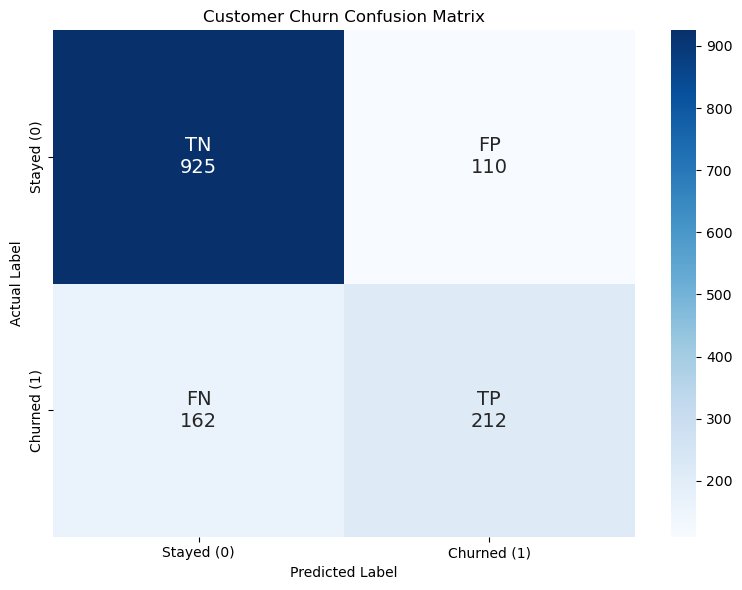

In [55]:
# Create a confusion matrix with prediction labels
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

# Add names to each result
labels = np.array([
    [f"TN\n{cm[0,0]}", f"FP\n{cm[0,1]}"],
    [f"FN\n{cm[1,0]}", f"TP\n{cm[1,1]}"]
])

# Draw the confusion matrix
plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=labels,
    fmt="",
    cmap="Blues",
    xticklabels=["Stayed (0)", "Churned (1)"],
    yticklabels=["Stayed (0)", "Churned (1)"],
    annot_kws={"size": 14}
)

plt.title("Customer Churn Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

### Balanced Logistic Regression

In [56]:
# Create a model that gives more attention to churned customers
balanced_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

# Train the balanced model
balanced_model.fit(X_train, y_train)

# Predict customer churn
y_pred_balanced = balanced_model.predict(X_test)

print("Balanced model trained successfully!")

Balanced model trained successfully!


In [57]:
# Evaluate the improved model
print("Balanced Model Accuracy:",
      round(accuracy_score(y_test, y_pred_balanced) * 100, 2), "%")

print("\nBalanced Model Classification Report:")
print(classification_report(y_test, y_pred_balanced))

Balanced Model Accuracy: 74.02 %

Balanced Model Classification Report:
              precision    recall  f1-score   support

           0       0.90      0.72      0.80      1035
           1       0.51      0.79      0.62       374

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



### Balanced Confusion Matrix

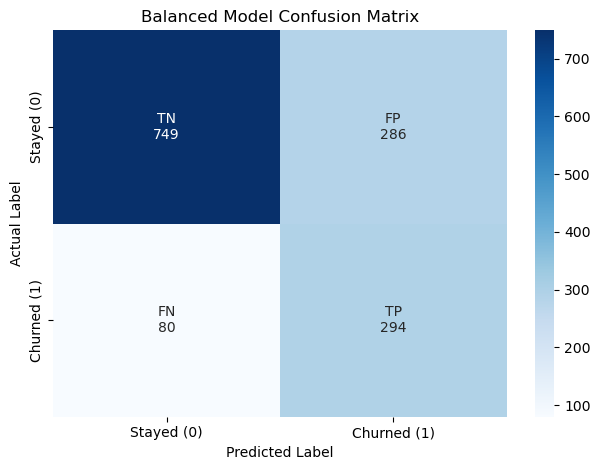

In [58]:
# Check the balanced model confusion matrix
cm_balanced = confusion_matrix(y_test, y_pred_balanced)

# Display the prediction results
sns.heatmap(
    cm_balanced,
    annot=np.array([
        [f"TN\n{cm_balanced[0,0]}", f"FP\n{cm_balanced[0,1]}"],
        [f"FN\n{cm_balanced[1,0]}", f"TP\n{cm_balanced[1,1]}"]
    ]),
    fmt="",
    cmap="Blues",
    xticklabels=["Stayed (0)", "Churned (1)"],
    yticklabels=["Stayed (0)", "Churned (1)"]
)

plt.title("Balanced Model Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()


### Compare Both Models

In [63]:
# Compare the performance of both models
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced)
    ]
})

# Display the comparison table
print("Model Performance Comparison")
print(comparison.round(3).to_string(index=False))

Model Performance Comparison
                       Model  Accuracy  Precision  Recall  F1-score
Original Logistic Regression     0.807      0.658   0.567     0.609
Balanced Logistic Regression     0.740      0.507   0.786     0.616


### Random Forest Model

In [64]:
# Import Random Forest
from sklearn.ensemble import RandomForestClassifier

# Create the Random Forest model
rf_model = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced"
)

# Train the model
rf_model.fit(X_train, y_train)

# Predict customer churn
y_pred_rf = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


### Random Forest Evaluation

In [65]:
# Evaluate the Random Forest model
print("Random Forest Accuracy:",
      round(accuracy_score(y_test, y_pred_rf) * 100, 2), "%")

print("\nRandom Forest Classification Report:")
print(classification_report(y_test, y_pred_rf))

Random Forest Accuracy: 78.78 %

Random Forest Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1035
           1       0.63      0.50      0.56       374

    accuracy                           0.79      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.78      0.79      0.78      1409



### Compare All Three Models

In [66]:
# Compare all three machine learning models
models_comparison = pd.DataFrame({
    "Model": [
        "Original Logistic Regression",
        "Balanced Logistic Regression",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred),
        accuracy_score(y_test, y_pred_balanced),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred),
        precision_score(y_test, y_pred_balanced),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred),
        recall_score(y_test, y_pred_balanced),
        recall_score(y_test, y_pred_rf)
    ],
    "F1-score": [
        f1_score(y_test, y_pred),
        f1_score(y_test, y_pred_balanced),
        f1_score(y_test, y_pred_rf)
    ]
})

# Display the final comparison
print(models_comparison.round(3).to_string(index=False))

                       Model  Accuracy  Precision  Recall  F1-score
Original Logistic Regression     0.807      0.658   0.567     0.609
Balanced Logistic Regression     0.740      0.507   0.786     0.616
               Random Forest     0.788      0.625   0.500     0.556


### Customer Churn Risk Prediction

In [67]:
# Calculate customer churn risk probabilities
churn_probabilities = balanced_model.predict_proba(X_test)[:, 1]

# Create a customer risk table
risk_results = pd.DataFrame({
    "Actual_Churn": y_test.values,
    "Churn_Probability": churn_probabilities
})

# Assign risk levels
risk_results["Risk_Level"] = pd.cut(
    risk_results["Churn_Probability"],
    bins=[-0.01, 0.30, 0.60, 1.00],
    labels=["Low", "Medium", "High"]
)

# Display the first 10 customers
print(risk_results.head(10))

   Actual_Churn  Churn_Probability Risk_Level
0             0           0.118378        Low
1             0           0.851640       High
2             0           0.141315        Low
3             0           0.664935       High
4             0           0.061424        Low
5             0           0.805352       High
6             0           0.699510       High
7             0           0.293819        Low
8             0           0.008837        Low
9             1           0.652162       High


### Customer Risk Summary

In [68]:
# Count customers in each risk category
risk_summary = risk_results["Risk_Level"].value_counts()

# Calculate the percentage of each risk category
risk_percentage = (
    risk_results["Risk_Level"].value_counts(normalize=True) * 100
)

# Create a summary table
risk_report = pd.DataFrame({
    "Customer_Count": risk_summary,
    "Percentage": risk_percentage
})

print("Customer Churn Risk Summary")
print(risk_report.round(2))

Customer Churn Risk Summary
            Customer_Count  Percentage
Risk_Level                            
Low                    602       42.73
High                   488       34.63
Medium                 319       22.64


### Customer Retention Strategy

In [73]:
# Suggest actions for each customer risk level
retention_actions = {
    "High": "Contact customer and offer suitable retention benefits",
    "Medium": "Follow up and improve customer experience",
    "Low": "Maintain good service and regular communication"
}

# Add recommended actions to the risk report
risk_report["Recommended_Action"] = risk_report.index.map(
    retention_actions
)

# Show the final retention strategy
print(risk_report.to_string())

            Customer_Count  Percentage                                      Recommended_Action
Risk_Level                                                                                    
Low                    602   42.725337         Maintain good service and regular communication
High                   488   34.634493  Contact customer and offer suitable retention benefits
Medium                 319   22.640170               Follow up and improve customer experience


### Customer Priority List

In [74]:
# Create a customer-level risk report
customer_report = pd.DataFrame({
    "Customer_ID": df.loc[X_test.index, "customerID"].values,
    "Churn_Probability": churn_probabilities,
    "Risk_Level": risk_results["Risk_Level"].values
})

# Sort customers from highest to lowest risk
customer_report = customer_report.sort_values(
    by="Churn_Probability",
    ascending=False
)

# Show the 10 customers with the highest churn risk
print("Top 10 High-Risk Customers")
print(customer_report.head(10).to_string(index=False))

Top 10 High-Risk Customers
Customer_ID  Churn_Probability Risk_Level
 5178-LMXOP           0.937634       High
 6861-XWTWQ           0.926252       High
 0295-PPHDO           0.926070       High
 2545-EBUPK           0.920873       High
 8884-ADFVN           0.920199       High
 1069-XAIEM           0.920197       High
 1400-MMYXY           0.918821       High
 8161-QYMTT           0.918552       High
 6023-YEBUP           0.918131       High
 6630-UJZMY           0.917253       High


### Export Customer Priority List

In [77]:
# Save the customer priority list in the current folder
customer_report.to_csv(
    "customer_priority_list.csv",
    index=False
)

print("Customer priority list saved successfully!")

Customer priority list saved successfully!


### Estimate Revenue at Risk

In [78]:
# Add monthly charges to the customer risk report
customer_report = customer_report.merge(
    df[["customerID", "MonthlyCharges"]],
    left_on="Customer_ID",
    right_on="customerID",
    how="left"
)

# Estimate the expected monthly revenue at risk
customer_report["Expected_Revenue_At_Risk"] = (
    customer_report["Churn_Probability"]
    * customer_report["MonthlyCharges"]
)

# Rank customers by estimated revenue at risk
customer_report = customer_report.sort_values(
    by="Expected_Revenue_At_Risk",
    ascending=False
)

# Show the top 10 customers
print("Top 10 Customers by Expected Revenue at Risk")
print(
    customer_report[
        ["Customer_ID", "MonthlyCharges",
         "Churn_Probability", "Expected_Revenue_At_Risk"]
    ].head(10).to_string(index=False)
)

Top 10 Customers by Expected Revenue at Risk
Customer_ID  MonthlyCharges  Churn_Probability  Expected_Revenue_At_Risk
 1400-MMYXY          105.90           0.918821                 97.303134
 3292-PBZEJ          111.40           0.863081                 96.147248
 4587-VVTOX          105.30           0.897144                 94.469286
 2027-FECZV          106.70           0.881138                 94.017466
 9221-OTIVJ          104.85           0.896040                 93.949819
 8884-ADFVN          101.95           0.920199                 93.814251
 6023-YEBUP          100.95           0.918131                 92.685303
 6861-XWTWQ           99.25           0.926252                 91.930516
 5052-PNLOS          105.35           0.866761                 91.313289
 6892-XPFPU          104.25           0.875260                 91.245902


### Expected Revenue at Risk

In [79]:
# Calculate the expected monthly revenue at risk
customer_report["Expected_Revenue_At_Risk"] = (
    customer_report["Churn_Probability"]
    * customer_report["MonthlyCharges"]
)

# Rank customers by expected revenue at risk
customer_report = customer_report.sort_values(
    by="Expected_Revenue_At_Risk",
    ascending=False
)

# Show the top 10 customers
print("Top 10 Customers by Revenue at Risk")
print(
    customer_report[
        ["Customer_ID", "MonthlyCharges",
         "Churn_Probability", "Expected_Revenue_At_Risk"]
    ].head(10).to_string(index=False)
)

Top 10 Customers by Revenue at Risk
Customer_ID  MonthlyCharges  Churn_Probability  Expected_Revenue_At_Risk
 1400-MMYXY          105.90           0.918821                 97.303134
 3292-PBZEJ          111.40           0.863081                 96.147248
 4587-VVTOX          105.30           0.897144                 94.469286
 2027-FECZV          106.70           0.881138                 94.017466
 9221-OTIVJ          104.85           0.896040                 93.949819
 8884-ADFVN          101.95           0.920199                 93.814251
 6023-YEBUP          100.95           0.918131                 92.685303
 6861-XWTWQ           99.25           0.926252                 91.930516
 5052-PNLOS          105.35           0.866761                 91.313289
 6892-XPFPU          104.25           0.875260                 91.245902


### Total Expected Revenue at Risk

In [80]:
# Calculate the total expected monthly revenue at risk
total_revenue_at_risk = customer_report[
    "Expected_Revenue_At_Risk"
].sum()

# Calculate the average revenue at risk per customer
average_revenue_at_risk = customer_report[
    "Expected_Revenue_At_Risk"
].mean()

print("Total Expected Monthly Revenue at Risk:",
      round(total_revenue_at_risk, 2))

print("Average Revenue at Risk per Customer:",
      round(average_revenue_at_risk, 2))

Total Expected Monthly Revenue at Risk: 42460.37
Average Revenue at Risk per Customer: 30.14


### Retention Budget Allocation

In [82]:
# Set the retention budget
retention_budget = 10000

# Estimate the retention cost per customer
cost_per_customer = 50

# Calculate how many customers the budget can cover
customers_to_contact = int(retention_budget / cost_per_customer)

# Select customers with the highest expected revenue at risk
priority_customers = customer_report.head(customers_to_contact)

# Calculate the total expected revenue at risk
selected_revenue = priority_customers["Expected_Revenue_At_Risk"].sum()

print("Retention Budget:", retention_budget)
print("Customers Selected:", len(priority_customers))
print("Expected Revenue at Risk:", round(selected_revenue, 2))

Retention Budget: 10000
Customers Selected: 200
Expected Revenue at Risk: 15193.44


In [83]:
# Display the top 10 priority customers
print("Top 10 Customers Selected for Retention")

print(
    priority_customers[
        [
            "Customer_ID",
            "MonthlyCharges",
            "Churn_Probability",
            "Expected_Revenue_At_Risk"
        ]
    ].head(10).to_string(index=False)
)

Top 10 Customers Selected for Retention
Customer_ID  MonthlyCharges  Churn_Probability  Expected_Revenue_At_Risk
 1400-MMYXY          105.90           0.918821                 97.303134
 3292-PBZEJ          111.40           0.863081                 96.147248
 4587-VVTOX          105.30           0.897144                 94.469286
 2027-FECZV          106.70           0.881138                 94.017466
 9221-OTIVJ          104.85           0.896040                 93.949819
 8884-ADFVN          101.95           0.920199                 93.814251
 6023-YEBUP          100.95           0.918131                 92.685303
 6861-XWTWQ           99.25           0.926252                 91.930516
 5052-PNLOS          105.35           0.866761                 91.313289
 6892-XPFPU          104.25           0.875260                 91.245902


### Export Retention Priority List

In [85]:
# Save the selected customers in the current folder
priority_customers.to_csv(
    "retention_priority_list.csv",
    index=False
)

print("File saved successfully!")
print("Total customers saved:", len(priority_customers))

File saved successfully!
Total customers saved: 200


## Model Optimization

### Threshold Tuning

In [87]:
# Get churn probabilities from the balanced model
churn_probabilities = balanced_model.predict_proba(X_test)[:, 1]

# Test different prediction thresholds
thresholds = [0.3, 0.4, 0.5, 0.6]

for threshold in thresholds:

    # Convert probabilities into predictions
    predictions = (churn_probabilities >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", round(accuracy_score(y_test, predictions), 3))
    print("Precision:", round(precision_score(y_test, predictions), 3))
    print("Recall:", round(recall_score(y_test, predictions), 3))
    print("F1-score:", round(f1_score(y_test, predictions), 3))


Threshold: 0.3
Accuracy: 0.653
Precision: 0.429
Recall: 0.925
F1-score: 0.586

Threshold: 0.4
Accuracy: 0.7
Precision: 0.465
Recall: 0.866
F1-score: 0.605

Threshold: 0.5
Accuracy: 0.74
Precision: 0.507
Recall: 0.786
F1-score: 0.616

Threshold: 0.6
Accuracy: 0.763
Precision: 0.541
Recall: 0.706
F1-score: 0.613


### Save Optimized Model

In [88]:
import joblib

# Save the optimized model
joblib.dump(balanced_model, "balanced_churn_model.pkl")

# Save the selected threshold
joblib.dump(0.5, "churn_threshold.pkl")

print("Optimized model saved successfully!")

Optimized model saved successfully!


In [89]:
import joblib

# Save the complete balanced model pipeline
joblib.dump(
    balanced_model,
    "complete_churn_pipeline.pkl"
)

print("Complete churn pipeline saved successfully!")

Complete churn pipeline saved successfully!


In [90]:
# Load the saved churn model
loaded_model = joblib.load("complete_churn_pipeline.pkl")

# Test the saved model
test_predictions = loaded_model.predict(X_test)

# Check if predictions match the original model
print("Saved model verification:",
      np.array_equal(test_predictions, y_pred_balanced))

print("Model loaded and tested successfully!")

Saved model verification: True
Model loaded and tested successfully!


### Customer Churn Analysis Dataset

In [91]:
# Export the cleaned customer dataset
df.to_csv(
    "customer_churn_analysis.csv",
    index=False
)

print("Customer churn dataset exported successfully!")
print("Total records:", len(df))

Customer churn dataset exported successfully!
Total records: 7043


### Customer Risk Report

In [92]:
# Export the customer risk report
customer_report.to_csv(
    "customer_risk_report.csv",
    index=False
)

print("Customer risk report exported successfully!")
print("Total customers:", len(customer_report))

Customer risk report exported successfully!
Total customers: 1409


### Retention Priority List

In [93]:
# Export the selected customers for retention
priority_customers.to_csv(
    "retention_priority_list.csv",
    index=False
)

print("Retention priority list exported successfully!")
print("Total customers:", len(priority_customers))

Retention priority list exported successfully!
Total customers: 200
